## mlpi26_Lect10_nbsup2.ipynb
# Supplement 2 — Recurrent networks on a mobile robot
### Heading, terrain and wheel slip from IMU and wheel-encoder sequences

*Companion to Raschka, Liu & Mirjalili, **Machine Learning with PyTorch and Scikit-Learn**, ch. 15
"Modeling Sequential Data Using Recurrent Neural Networks". The main lecture used a CNC turning
cell; this supplement re-teaches the same ideas on a different machine — a small
differential-drive rover — so that you see each idea twice, in two settings.*

**What you will be able to do after this notebook**

1. Recognise a *recurrent update* as something robotics already does: dead reckoning,
   ψₜ = ψₜ₋₁ + Δt·gyroₜ, is an RNN with one hidden unit, W_hh = 1 and no nonlinearity.
2. Choose the sequence shape (many-to-one, many-to-many) from the question being asked.
3. Train a vanilla RNN, an LSTM and a GRU on the same task and explain, with a measured
   gradient, why the vanilla RNN loses.
4. Look inside a trained LSTM and find the units that carry the robot's heading.
5. Batch ragged sequences three ways — padding, packing and bucketing — and know when each one
   changes the answer.
6. Judge every network against the physics baseline it has to beat.

**Prerequisites:** the ch. 15 lecture (RNN cell, BPTT, LSTM gates), basic PyTorch training loops.
Everything here is synthetic and generated inline — no downloads. Runtime ≈ 4–5 min on 2 CPU cores.

In [1]:
import sys, time, json
import numpy as np
import torch, torch.nn as nn, torch.nn.functional as F
from torch.nn.utils.rnn import pad_sequence, pack_padded_sequence, pad_packed_sequence
import sklearn
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from scipy.stats import kurtosis
import matplotlib.pyplot as plt
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": .3,
                     "axes.spines.top": False, "axes.spines.right": False})
torch.set_num_threads(2)
print("python", sys.version.split()[0], "| torch", torch.__version__, "| numpy", np.__version__,
      "| sklearn", sklearn.__version__)

python 3.13.16 | torch 2.14.1+cu130 | numpy 2.5.3 | sklearn 1.9.1


## 1. The robot and its sensors

A two-wheeled rover (track width 0.5 m) drives runs of 8–20 s on one of three floors —
**concrete, grass, gravel** — while logging seven channels at **10 Hz**:

| channel | what it is | how it lies |
|---|---|---|
| `v_cmd`, `w_cmd` | commanded speed and turn rate | it is a wish, not a measurement |
| `v_left`, `v_right` | wheel-encoder speeds | over-reads when a wheel **slips** |
| `gyro_z` | yaw-rate gyro | small noise, plus a constant **bias** that differs every run |
| `acc_x` | longitudinal accelerometer | noisy derivative of speed |
| `acc_z` | vertical accelerometer | carries the **terrain vibration** signature |

Three questions, three labels per run:

* **terrain** — one class per run (*many-to-one*);
* **slip[t]** — is a wheel slipping at step *t* (*many-to-many*, synchronised);
* **ψ[t]** — the true heading at every step (*many-to-many regression*).

The true heading is exactly what a robot cannot measure directly. Integrating the gyro drifts
because of the bias; differencing the wheels is ruined by slip. A good estimator has to *fuse*
the two over time — that is a job for a hidden state.

The generator below is the whole simulator. Read `make_run` once: every number in this notebook
comes from it.

In [2]:
import numpy as np

DT = 0.10                 # 10 Hz
TRACK = 0.50              # wheel separation [m]
CHANNELS = ["v_cmd", "w_cmd", "v_left", "v_right", "gyro_z", "acc_x", "acc_z"]
TERRAINS = ["concrete", "grass", "gravel"]
# vibration model of acc_z: AR(1) coefficient, innovation std (per m/s), impulse rate
VIB = {"concrete": (0.00, 0.30, 0.00),
       "grass":    (0.55, 0.30, 0.00),
       "gravel":   (0.00, 0.30, 0.06)}
SLIP_RATE = {"concrete": 0.6, "grass": 1.6, "gravel": 2.4}     # episodes per 10 s
ROLL = {"concrete": 0.02, "grass": 0.10, "gravel": 0.06}         # speed loss fraction
GYRO_NOISE, GYRO_BIAS, ENC_NOISE, ACC_NOISE = 0.03, 0.04, 0.03, 0.08


def _piecewise(rng, T, seg_s, choices_fn):
    out = np.empty(T)
    t = 0
    while t < T:
        n = int(rng.uniform(*seg_s) / DT)
        out[t:t + n] = choices_fn()
        t += n
    return out


def _lag(x, tau):
    a = DT / (tau + DT)
    y = np.empty_like(x)
    y[0] = x[0]
    for t in range(1, len(x)):
        y[t] = y[t - 1] + a * (x[t] - y[t - 1])
    return y


def make_run(rng, terrain=None, T=None):
    terrain = terrain if terrain is not None else TERRAINS[rng.integers(3)]
    T = T if T is not None else 10 * int(rng.integers(8, 21))  # 8-20 s, multiples of 10
    v_cmd = _piecewise(rng, T, (1.5, 4.0), lambda: rng.uniform(0.3, 1.0))
    w_cmd = _piecewise(rng, T, (1.0, 3.0),
                       lambda: 0.0 if rng.random() < 0.35 else rng.uniform(-0.9, 0.9))
    v = _lag(v_cmd, 0.35) * (1 - ROLL[terrain])
    w = _lag(w_cmd, 0.25)
    psi = np.cumsum(w) * DT

    # slip episodes: wheels spin faster than the body moves
    slip = np.zeros(T)
    extra_l = np.zeros(T)
    extra_r = np.zeros(T)
    n_ep = rng.poisson(SLIP_RATE[terrain] * T * DT / 10.0)
    for _ in range(n_ep):
        s = int(rng.integers(0, T - 8))
        d = int(rng.uniform(0.8, 2.5) / DT)
        e = min(T, s + d)
        slip[s:e] = 1
        env = np.sin(np.linspace(0, np.pi, e - s)) ** 0.5
        side = rng.random()
        extra_l[s:e] += env * rng.uniform(0.10, 0.35) * (side < 0.7)
        extra_r[s:e] += env * rng.uniform(0.10, 0.35) * (side > 0.3)
    # slipping wheels also drag the body a little
    v_true = v * (1 - 0.15 * slip)

    v_l = v_true - w * TRACK / 2 + extra_l + rng.normal(0, ENC_NOISE, T)
    v_r = v_true + w * TRACK / 2 + extra_r + rng.normal(0, ENC_NOISE, T)
    gyro_bias = rng.normal(0, GYRO_BIAS)                       # per-run, unknown to the model
    gyro = w + gyro_bias + rng.normal(0, GYRO_NOISE, T)
    acc_x = np.gradient(v_true, DT) + rng.normal(0, ACC_NOISE, T)

    a, s, imp = VIB[terrain]
    e = rng.normal(0, s, T) * (0.4 + v_true)
    z = np.empty(T)
    z[0] = e[0]
    for t in range(1, T):
        z[t] = a * z[t - 1] + e[t]
    if imp > 0:
        hits = rng.random(T) < imp
        z += hits * rng.choice([-1, 1], T) * rng.uniform(0.8, 1.6, T) * (0.4 + v_true)
    acc_z = z + rng.normal(0, ACC_NOISE, T)

    X = np.stack([v_cmd, w_cmd, v_l, v_r, gyro, acc_x, acc_z], 1).astype(np.float32)
    return X, dict(terrain=TERRAINS.index(terrain), slip=slip.astype(np.float32),
                   psi=psi.astype(np.float32), T=T, v=v_true, w=w, gyro_bias=gyro_bias)


def make_dataset(n, seed, T=None):
    rng = np.random.default_rng(seed)
    Xs, ys = [], []
    for i in range(n):
        X, y = make_run(rng, terrain=TERRAINS[i % 3], T=T)
        Xs.append(X)
        ys.append(y)
    return Xs, ys

In [3]:
Xtr_l, ytr = make_dataset(900, 7)      # training runs
Xva_l, yva = make_dataset(300, 108)    # (kept aside; not needed for the results below)
Xte_l, yte = make_dataset(600, 209)    # test runs
lens = [len(x) for x in Xtr_l]
print(f"train {len(Xtr_l)}  val {len(Xva_l)}  test {len(Xte_l)}  | length {min(lens)}–{max(lens)} steps,"
      f" {len(set(lens))} distinct lengths")
for k, t in enumerate(TERRAINS):
    print(f"  {t:9s} slip fraction {np.concatenate([y['slip'] for y in ytr if y['terrain']==k]).mean():.3f}")
allx = np.concatenate(Xtr_l)
mu, sd = allx.mean(0), allx.std(0)     # standardise with TRAINING statistics only
PSI_SD = float(np.concatenate([y["psi"] for y in ytr]).std())
print("heading scale (train std) =", round(PSI_SD, 3), "rad")

train 900  val 300  test 600  | length 80–200 steps, 13 distinct lengths
  concrete  slip fraction 0.085
  grass     slip fraction 0.210
  gravel    slip fraction 0.317
heading scale (train std) = 1.708 rad


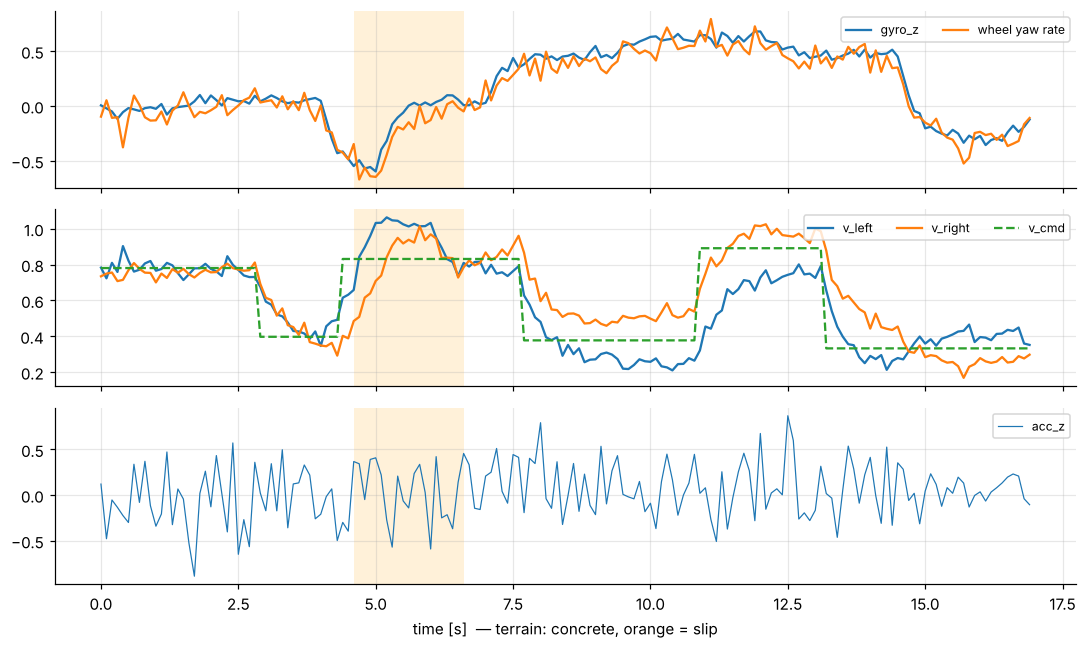

In [4]:
i = 0
X, y = Xte_l[i], yte[i]
t = np.arange(len(X)) * DT
fig, ax = plt.subplots(3, 1, figsize=(10, 6), sharex=True)
for a in ax:
    for k in np.where(y["slip"] > 0)[0]:
        a.axvspan(t[k], t[k] + DT, color="orange", alpha=.15, lw=0)
ax[0].plot(t, X[:, 4], label="gyro_z"); ax[0].plot(t, (X[:, 3] - X[:, 2]) / TRACK, label="wheel yaw rate")
ax[1].plot(t, X[:, 2], label="v_left"); ax[1].plot(t, X[:, 3], label="v_right"); ax[1].plot(t, X[:, 0], "--", label="v_cmd")
ax[2].plot(t, X[:, 6], lw=.8, label="acc_z")
for a in ax: a.legend(loc="upper right", fontsize=8, ncol=3)
ax[2].set_xlabel(f"time [s]  — terrain: {TERRAINS[y['terrain']]}, orange = slip")
plt.tight_layout(); plt.show()

## 2. Dead reckoning *is* a recurrent network

The ch. 15 RNN update is hₜ = tanh(W_xh xₜ + W_hh hₜ₋₁ + b). Strip away the tanh, set the
hidden size to 1, W_hh = 1 and W_xh = Δt on the gyro channel, and you get

$$\psi_t = 1\cdot\psi_{t-1} + \Delta t\cdot \text{gyro}_t ,$$

the textbook heading integrator. Two lessons follow immediately:

* **The hidden state is a state estimate.** Everything the robot needs to remember about the
  past is squeezed into hₜ — exactly like the state vector of a Kalman filter.
* **Integration needs a recurrent weight of exactly 1.** With ρ = W_hh < 1 an impulse decays as
  ρᵏ; the *memory half-life* is ln 0.5 / ln ρ steps. A trained tanh RNN has to hold ρ ≈ 1
  without exploding — that is the vanishing/exploding-gradient problem seen from the inside.

linear RNN vs np.cumsum, max |diff| = 9.536743e-07


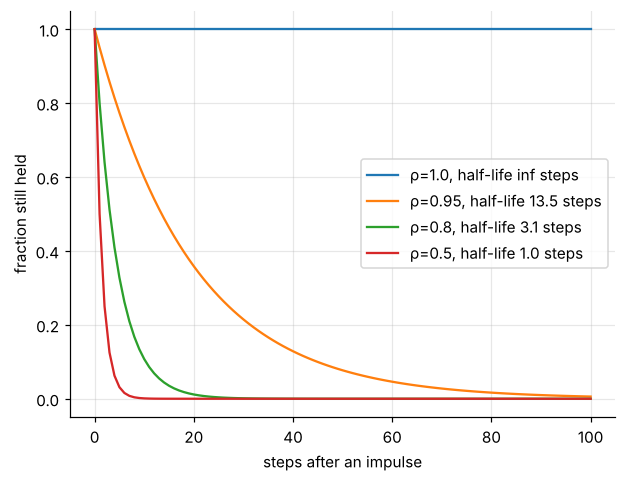

In [5]:
x0 = Xte_l[0]
h, hs = 0.0, []
for g in x0[:, 4]:
    h = 1.0 * h + DT * g          # W_hh = 1, W_xh = dt, no nonlinearity
    hs.append(h)
print("linear RNN vs np.cumsum, max |diff| =", np.abs(np.array(hs) - np.cumsum(x0[:, 4]) * DT).max())

lags = np.arange(101)
for r in (1.0, 0.95, 0.8, 0.5):
    hl = np.log(.5) / np.log(r) if r < 1 else np.inf
    plt.plot(lags, r ** lags, label=f"ρ={r}, half-life {hl:.1f} steps")
plt.xlabel("steps after an impulse"); plt.ylabel("fraction still held"); plt.legend(); plt.show()

The same forward pass, written out for a real `nn.RNN` (8 hidden units, tanh). If the hand loop
and PyTorch agree to float32 precision, you know exactly what the layer computes.

In [6]:
torch.manual_seed(0)
rnn = nn.RNN(7, 8, batch_first=True)
xb = torch.from_numpy(((x0 - mu) / sd)[None].astype(np.float32))
W_ih, W_hh, b = rnn.weight_ih_l0, rnn.weight_hh_l0, rnn.bias_ih_l0 + rnn.bias_hh_l0
hh, outs = torch.zeros(8), []
with torch.no_grad():
    for t in range(xb.shape[1]):
        hh = torch.tanh(W_ih @ xb[0, t] + W_hh @ hh + b)
        outs.append(hh)
    ref, _ = rnn(xb)
print("manual loop vs nn.RNN, max |diff| =", float((torch.stack(outs) - ref[0]).abs().max()))

manual loop vs nn.RNN, max |diff| = 1.4901161193847656e-07


## 3. Ragged runs: pad, pack — or bucket

Runs last 8–20 s, so a batch of runs is ragged. Three options:

| option | how | what can go wrong |
|---|---|---|
| **pad** | `pad_sequence`, then mask the loss | the final state `h_n` has read the padding; a *bidirectional* layer reads padding *first* |
| **pack** | `pack_padded_sequence(..., enforce_sorted=False)` | correct, but on CPU it is slow (one small matmul per step per length) |
| **bucket** | put runs of equal length in the same batch | nothing — no padding exists. Needs enough runs per length |

The cell below measures all three on four runs of length 40, 30, 20 and 10. Two facts to take
away: for a *forward* RNN the output **at step L−1** is unaffected by padding that comes later
(causality), but `h_n` and every bidirectional output are wrong unless you pack.

In [7]:
Xall = [torch.from_numpy(((x - mu) / sd).astype(np.float32)) for x in Xte_l]
torch.manual_seed(3)
lstm_d = nn.LSTM(7, 16, batch_first=True)
bil = nn.LSTM(7, 16, batch_first=True, bidirectional=True)
lens4 = [40, 30, 20, 10]
seqs = [Xall[i][:L] for i, L in zip(range(4), lens4)]
padded = pad_sequence(seqs, batch_first=True)          # (4, 40, 7), 37.5 % zeros
L_t = torch.tensor(lens4)
with torch.no_grad():
    single = [lstm_d(s[None]) for s in seqs]           # ground truth: one run at a time
    outp, (hn, _) = lstm_d(padded)
    pk = pack_padded_sequence(padded, L_t, batch_first=True, enforce_sorted=False)
    _, (hn_p, _) = lstm_d(pk)
    sb = [bil(s[None])[0][0] for s in seqs]
    ob, _ = bil(padded)
    obp, _ = pad_packed_sequence(bil(pk)[0], batch_first=True)
rows = {
  "forward: output at step L-1, padded": max(float((outp[k, L-1] - single[k][0][0, -1]).abs().max()) for k, L in enumerate(lens4)),
  "forward: h_n, padded":               max(float((hn[0, k] - single[k][1][0][0, 0]).abs().max()) for k in range(4)),
  "forward: h_n, packed":               max(float((hn_p[0, k] - single[k][1][0][0, 0]).abs().max()) for k in range(4)),
  "bidirectional outputs, padded":      max(float((ob[k, :L] - sb[k]).abs().max()) for k, L in enumerate(lens4)),
  "bidirectional outputs, packed":      max(float((obp[k, :L] - sb[k]).abs().max()) for k, L in enumerate(lens4)),
}
for k, v in rows.items(): print(f"{k:40s} max |error| = {v:.2e}")

forward: output at step L-1, padded      max |error| = 0.00e+00
forward: h_n, padded                     max |error| = 1.63e-01
forward: h_n, packed                     max |error| = 5.96e-08
bidirectional outputs, padded            max |error| = 9.90e-02
bidirectional outputs, packed            max |error| = 8.94e-08


In [8]:
xb = torch.randn(128, 200, 7); Lb = torch.randint(80, 201, (128,))
m_ = nn.LSTM(7, 48, batch_first=True)
t0 = time.time()
for _ in range(3):
    o, _ = m_(pack_padded_sequence(xb, Lb, batch_first=True, enforce_sorted=False)); o.data.sum().backward()
t_packed = (time.time() - t0) / 3
t0 = time.time()
for _ in range(3):
    o, _ = m_(xb); o.sum().backward()
t_plain = (time.time() - t0) / 3
print(f"one batch fwd+bwd: packed {t_packed:.3f} s, plain (bucketed) {t_plain:.3f} s  -> {t_packed/t_plain:.1f}x")

one batch fwd+bwd: packed 1.064 s, plain (bucketed) 0.119 s  -> 8.9x


Because our run lengths are multiples of 10 steps, there are only 13 distinct lengths and every
bucket holds dozens of runs. So the rest of this notebook **buckets**: each batch contains runs of
one length, no padding, no masks, no packing. The helpers below are the whole training
infrastructure. `open_gates_` sets the LSTM forget-gate bias (and the GRU update-gate bias) to +1,
the fix from the main lecture.

In [9]:
import time
import numpy as np
import torch
import torch.nn as nn
from torch.nn.utils.rnn import pad_sequence, pack_padded_sequence, pad_packed_sequence

torch.set_num_threads(2)


class Buckets:
    '''Groups runs by length. X: list of (T, C) arrays; Y: list of per-run targets.'''
    def __init__(self, Xs, Ys, mu, sd):
        self.groups = {}
        for i, (x, y) in enumerate(zip(Xs, Ys)):
            self.groups.setdefault(len(x), []).append(i)
        self.data = {}
        for T, idx in self.groups.items():
            X = torch.from_numpy(np.stack([(Xs[i] - mu) / sd for i in idx]).astype(np.float32))
            Y = torch.as_tensor(np.stack([Ys[i] for i in idx]))
            self.data[T] = (X, Y, np.array(idx))
        self.n = len(Xs)

    def batches(self, bs, gen=None):
        out = []
        for T, (X, Y, idx) in self.data.items():
            perm = torch.randperm(len(X), generator=gen) if gen is not None else torch.arange(len(X))
            for b in perm.split(bs):
                out.append((X[b], Y[b], idx[b.numpy()]))
        if gen is not None:
            order = torch.randperm(len(out), generator=gen).tolist()
            out = [out[i] for i in order]
        return out


class SeqNet(nn.Module):
    '''RNN / LSTM / GRU + small head. per_step=True gives an output at every time step.'''
    def __init__(self, cell, n_in, n_hidden, n_out, per_step=False,
                 bidirectional=False, open_gates=True):
        super().__init__()
        rnn_cls = {"rnn": nn.RNN, "lstm": nn.LSTM, "gru": nn.GRU}[cell]
        self.cell, self.per_step = cell, per_step
        self.rnn = rnn_cls(n_in, n_hidden, batch_first=True, bidirectional=bidirectional)
        k = 2 if bidirectional else 1
        self.head = nn.Sequential(nn.Linear(k * n_hidden, 32), nn.ReLU(), nn.Linear(32, n_out))
        if open_gates and cell in ("lstm", "gru"):
            open_gates_(self.rnn, cell, n_hidden)

    def forward(self, x):
        out, _ = self.rnn(x)                 # (B, T, k*H)
        if self.per_step:
            return self.head(out)
        if self.rnn.bidirectional:           # forward half at the end, backward half at the start
            H = self.rnn.hidden_size
            last = torch.cat([out[:, -1, :H], out[:, 0, H:]], 1)
        else:
            last = out[:, -1]
        return self.head(last)


def open_gates_(rnn, cell, h, value=1.0):
    '''LSTM: forget-gate bias +value.  GRU: update-gate bias -value would REDUCE memory in
    PyTorch's convention (h = (1-z)*n + z*h), so for GRU we set z's bias to +value.'''
    for name, p in rnn.named_parameters():
        if name.startswith("bias_ih"):
            with torch.no_grad():
                p[h:2 * h].fill_(value)


def train(model, loss_fn, data, epochs, lr=3e-3, bs=64, seed=1234,
          eval_fn=None, clip=1.0, log=False, record_grad=False):
    torch.manual_seed(seed)
    gen = torch.Generator().manual_seed(seed)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs)
    hist = []
    t0 = time.time()
    for ep in range(epochs):
        model.train()
        tot, nb = 0.0, 0
        for X, Y, _ in data.batches(bs, gen):
            opt.zero_grad()
            loss = loss_fn(model(X), Y)
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), clip)
            opt.step()
            tot += loss.item()
            nb += 1
        sched.step()
        rec = {"epoch": ep + 1, "train_loss": tot / nb}
        if eval_fn is not None:
            rec.update(eval_fn(model))
        hist.append(rec)
        if log:
            print(rec, flush=True)
    return hist, time.time() - t0


@torch.no_grad()
def predict(model, data):
    '''Run the model bucket by bucket; returns {run index: output tensor}.'''
    model.eval()
    res = {}
    for X, Y, idx in data.batches(256):
        out = model(X)
        for k, i in enumerate(idx):
            res[int(i)] = out[k]
    return res

## 4. Project 1 — heading from noisy sensors (many-to-many regression)

Target: ψ[t] at every step (scaled by its training std). Two physics baselines that use one
sensor each:

* **integrate the gyro** — immune to slip, but the per-run bias makes it drift linearly;
* **wheel odometry** — ψ̇ = (v_right − v_left)/track — no bias, but every slip episode adds a
  heading jump.

Neither is good. A network sees *both* and can learn to trust the wheels when they agree with
the gyro (and so estimate the gyro bias), and to trust the gyro during slip.

In [10]:
tr_h = Buckets(Xtr_l, [y["psi"] / PSI_SD for y in ytr], mu, sd)
te_h = Buckets(Xte_l, [y["psi"] / PSI_SD for y in yte], mu, sd)
mse_seq = lambda out, y: F.mse_loss(out[..., 0], y)
rmse = lambda a: float(np.sqrt(np.mean(np.square(a))))

est = {"gyro":   {i: np.cumsum(x[:, 4]) * DT for i, x in enumerate(Xte_l)},
       "wheels": {i: np.cumsum((x[:, 3] - x[:, 2]) / TRACK) * DT for i, x in enumerate(Xte_l)}}
heading_models = {}
for cell in ("rnn", "lstm", "gru"):
    torch.manual_seed(1)
    m = SeqNet(cell, 7, 48, 1, per_step=True)
    hist, secs = train(m, mse_seq, tr_h, epochs=30)
    heading_models[cell] = m
    Pm = predict(m, te_h)
    est[cell] = {i: Pm[i][:, 0].numpy() * PSI_SD for i in Pm}
    print(f"{cell:5s} {sum(p.numel() for p in m.parameters()):6d} params  {secs:5.1f} s  final train loss {hist[-1]['train_loss']:.4f}")

print(f"\n{'estimator':10s} {'RMSE at end [rad]':>18s} {'RMSE all steps':>15s}")
for k, e in est.items():
    print(f"{k:10s} {rmse([e[i][-1] - yte[i]['psi'][-1] for i in range(len(yte))]):18.3f}"
          f" {rmse(np.concatenate([e[i] - yte[i]['psi'] for i in range(len(yte))])):15.3f}")

rnn     4337 params   22.6 s  final train loss 0.2145


lstm   12545 params   25.1 s  final train loss 0.0032


gru     9809 params   62.0 s  final train loss 0.0013

estimator   RMSE at end [rad]  RMSE all steps
gyro                    0.587           0.367
wheels                  0.662           0.484
rnn                     1.334           0.855
lstm                    0.206           0.116
gru                     0.126           0.069


Read the table before the plots. The vanilla RNN (1.33 rad at the end of
a run) is **worse than either sensor on its own** — it has not learned to integrate. The LSTM
(0.21) and the GRU (0.13) beat the best single
sensor (0.59, gyro) by a factor of 4.7
for the GRU: they really have learned sensor fusion.

The error-vs-time plot makes the mechanism visible: the gyro baseline grows linearly (bias ×
time), wheel odometry grows in steps (slip episodes), and the vanilla RNN's error grows fastest
of all.

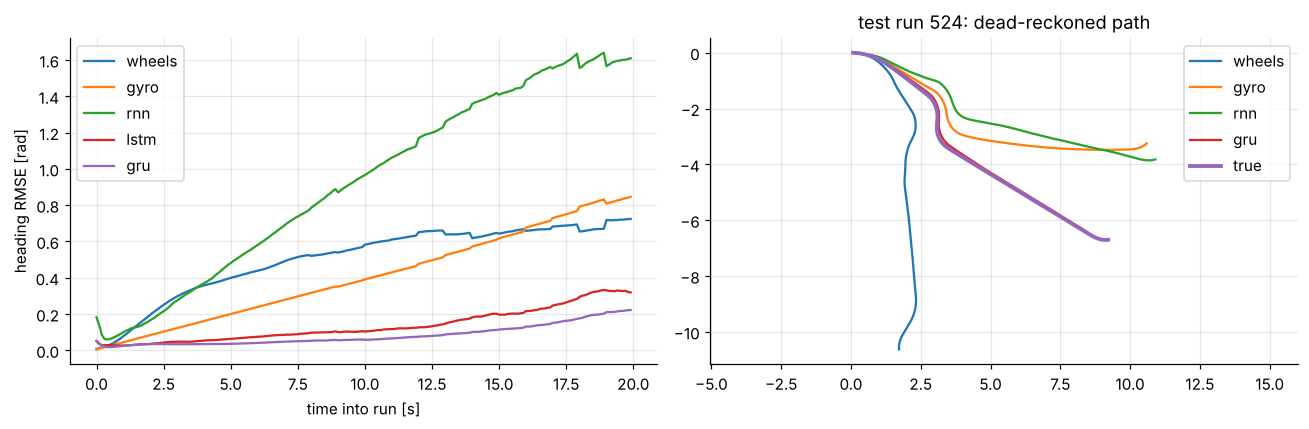

In [11]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
tt = np.arange(200) * DT
for k in ("wheels", "gyro", "rnn", "lstm", "gru"):
    e = [rmse([est[k][i][t] - yte[i]["psi"][t] for i in range(len(yte)) if len(yte[i]["psi"]) > t]) for t in range(200)]
    ax[0].plot(tt, e, label=k)
ax[0].set_xlabel("time into run [s]"); ax[0].set_ylabel("heading RMSE [rad]"); ax[0].legend()
ex = max([i for i in range(len(yte)) if len(yte[i]["psi"]) == 200],
         key=lambda i: yte[i]["slip"].sum() * (abs(yte[i]["psi"]).max() > 1.5))
v = yte[ex]["v"]
for k in ("wheels", "gyro", "rnn", "gru", "true"):
    psi = yte[ex]["psi"] if k == "true" else est[k][ex]
    xx, yy = np.cumsum(v * np.cos(psi)) * DT, np.cumsum(v * np.sin(psi)) * DT
    ax[1].plot(xx, yy, lw=2.5 if k == "true" else 1.5, label=k)
ax[1].set_aspect("equal", "datalim"); ax[1].legend(); ax[1].set_title(f"test run {ex}: dead-reckoned path")
plt.tight_layout(); plt.show()

## 5. Why the vanilla RNN loses: measure the gradient

For the final heading estimate ψ̂_T, the *ideal* integrator has ∂ψ̂_T/∂gyro_{T−k} = Δt for
every lag k — a flat line. BPTT multiplies one Jacobian per step, so in a vanilla RNN that
derivative behaves like ρᵏ. We measure it directly with autograd, on 64 test runs of length 200,
for each model at initialisation and after training.

rnn   init: lag 10 2.5e-03, lag 100 1.2e-24   trained: lag 10 0.28, lag 100 0.14, lag 190 1.40


lstm  init: lag 10 1.0e-01, lag 100 9.6e-08   trained: lag 10 0.35, lag 100 0.26, lag 190 0.25


gru   init: lag 10 7.3e-02, lag 100 2.5e-09   trained: lag 10 0.43, lag 100 0.11, lag 190 0.34


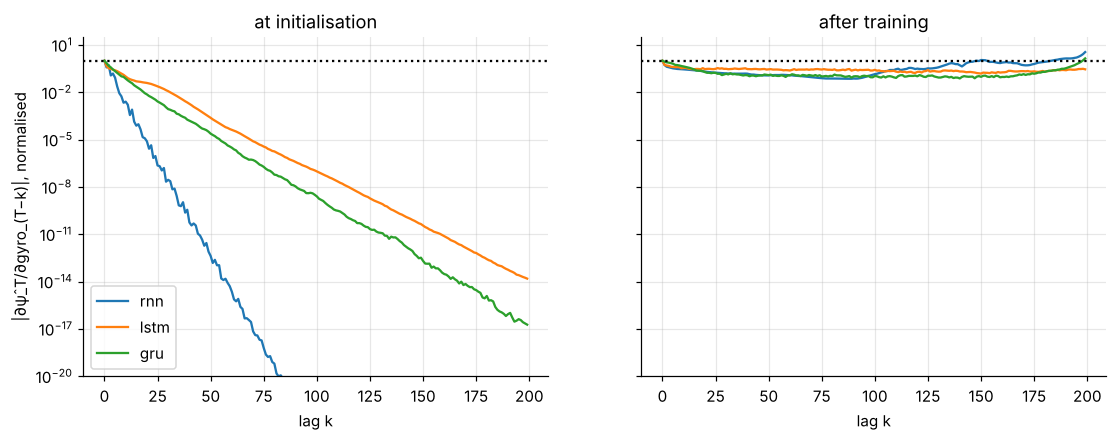

In [12]:
X200 = te_h.data[200][0][:64]

def grad_reach(m):
    x = X200.clone().requires_grad_(True)
    m.eval()
    m(x)[:, -1, 0].sum().backward()
    g = x.grad[:, :, 4].abs().mean(0).numpy()[::-1]     # gradient w.r.t. gyro, indexed by lag
    return g / g[0]

fig, ax = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for cell in ("rnn", "lstm", "gru"):
    torch.manual_seed(1)
    g0 = grad_reach(SeqNet(cell, 7, 48, 1, per_step=True))
    g1 = grad_reach(heading_models[cell])
    ax[0].semilogy(np.maximum(g0, 1e-30), label=cell); ax[1].semilogy(np.maximum(g1, 1e-30), label=cell)
    print(f"{cell:5s} init: lag 10 {g0[10]:.1e}, lag 100 {g0[100]:.1e}   trained: lag 10 {g1[10]:.2f}, lag 100 {g1[100]:.2f}, lag 190 {g1[190]:.2f}")
for a, t in zip(ax, ("at initialisation", "after training")):
    a.axhline(1, color="k", ls=":"); a.set_title(t); a.set_xlabel("lag k"); a.set_ylim(1e-20, 30)
ax[0].set_ylabel("|∂ψ̂_T/∂gyro_(T−k)|, normalised"); ax[0].legend(); plt.show()

At initialisation **every** model's gradient dies within a few dozen steps — even the LSTM with
its forget gate opened. What differs is what training can do from there. The LSTM and GRU end up
with a nearly flat profile: an early gyro sample matters about as much as a recent one, which is
what integration requires. The vanilla RNN's profile after training is erratic (it even rises
again at the longest lags): its only memory path runs through W_hh and tanh, so it can either
forget or amplify, but not hold.

## 6. Inside the trained LSTM: who is carrying the heading?

We step the trained LSTM by hand — the four gate equations from the lecture — check the result
against `nn.LSTM`, and then correlate every cell-state unit cₜ with the true heading ψₜ.

manual LSTM vs nn.LSTM, max |diff| = 5.960464477539062e-07
best unit 4: r = 0.974;  units with |r| > 0.9: 19 of 48
mean forget gate: all units 0.727, unit 4: 0.757


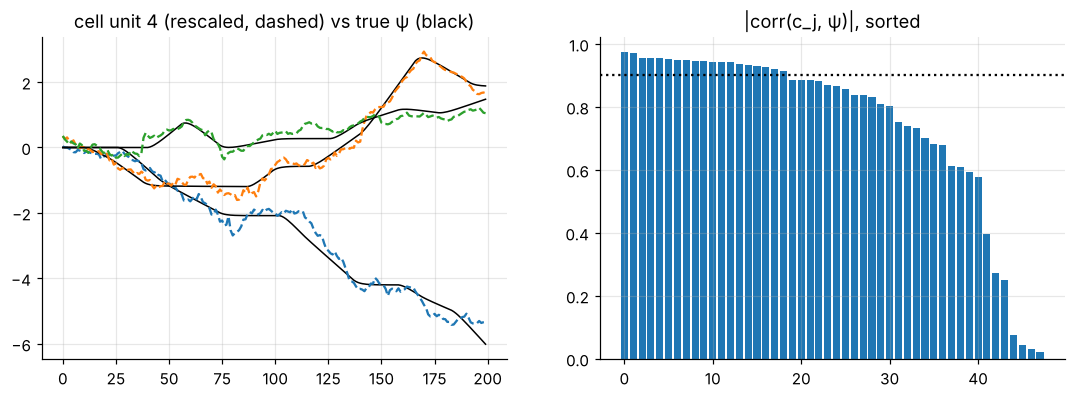

In [13]:
def manual_lstm(rnn, x):
    H = rnn.hidden_size
    Wi, Wh, b = rnn.weight_ih_l0, rnn.weight_hh_l0, rnn.bias_ih_l0 + rnn.bias_hh_l0
    h = torch.zeros(x.shape[0], H); c = torch.zeros(x.shape[0], H)
    Hs, Cs, Fs = [], [], []
    for t in range(x.shape[1]):
        i, f, g, o = (x[:, t] @ Wi.T + h @ Wh.T + b).split(H, 1)   # PyTorch gate order: i, f, g, o
        i, f, g, o = torch.sigmoid(i), torch.sigmoid(f), torch.tanh(g), torch.sigmoid(o)
        c = f * c + i * g
        h = o * torch.tanh(c)
        Hs.append(h); Cs.append(c); Fs.append(f)
    return torch.stack(Hs, 1), torch.stack(Cs, 1), torch.stack(Fs, 1)

lstm_h = heading_models["lstm"]
with torch.no_grad():
    Hm, Cm, Fm = manual_lstm(lstm_h.rnn, X200)
    ref, _ = lstm_h.rnn(X200)
print("manual LSTM vs nn.LSTM, max |diff| =", float((Hm - ref).abs().max()))
psi200 = np.stack([yte[i]["psi"] for i in te_h.data[200][2][:64]])
cc, pp = Cm.reshape(-1, Cm.shape[-1]).numpy(), psi200.reshape(-1)
corr = np.array([np.corrcoef(cc[:, j], pp)[0, 1] for j in range(cc.shape[1])])
best = int(np.nanargmax(np.abs(corr)))
print(f"best unit {best}: r = {corr[best]:.3f};  units with |r| > 0.9: {(np.abs(corr) > 0.9).sum()} of 48")
print(f"mean forget gate: all units {Fm.mean():.3f}, unit {best}: {Fm[..., best].mean():.3f}")
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
for k in range(3):
    cs, ps = Cm[k, :, best].numpy(), psi200[k]
    a, b0 = np.linalg.lstsq(np.vstack([cs, np.ones_like(cs)]).T, ps, rcond=None)[0]
    ax[0].plot(ps, "k", lw=1); ax[0].plot(a * cs + b0, "--")
ax[0].set_title(f"cell unit {best} (rescaled, dashed) vs true ψ (black)")
ax[1].bar(range(48), np.sort(np.abs(corr))[::-1]); ax[1].axhline(.9, ls=":", color="k")
ax[1].set_title("|corr(c_j, ψ)|, sorted"); plt.show()

The heading is not hidden in one place — 19 of the 48 cell units
correlate with ψ at |r| > 0.9, the best at r = 0.974. The network has built a
**distributed state estimate**.

One honest surprise: the forget gates of those units are *not* ≈ 1 (mean
0.76 for the best unit). The textbook picture —
"f ≈ 1, the cell is a pure integrator" — is one solution, not the only one; this network
refreshes the stored heading through the recurrent loop c → h → g at each step. Gradient
descent finds *a* memory mechanism, not necessarily the one we would design.

## 7. Project 2 — terrain classification (many-to-one)

One label per run, read from the last time step. The vibration on `acc_z` differs by floor:
concrete is white noise, grass is low-pass (correlated), gravel has random impulses. Any single
sample is ambiguous; the model has to **accumulate evidence**.

As an honest baseline we also fit a logistic regression on five hand-made vibration features
(std, lag-1 autocorrelation, kurtosis, speed-normalised std, mean |Δ|).

In [14]:
tr_t = Buckets(Xtr_l, [y["terrain"] for y in ytr], mu, sd)
te_t = Buckets(Xte_l, [y["terrain"] for y in yte], mu, sd)
yt_te = np.array([y["terrain"] for y in yte])
terrain_models = {}
for cell in ("rnn", "lstm", "gru"):
    torch.manual_seed(1)
    m = SeqNet(cell, 7, 48, 3)
    hist, secs = train(m, lambda o, y: F.cross_entropy(o, y), tr_t, epochs=25)
    Pm = predict(m, te_t)
    pred = np.array([Pm[i].argmax().item() for i in range(len(yte))])
    terrain_models[cell] = (m, pred)
    print(f"{cell:5s} test accuracy {(pred == yt_te).mean():.3f}   ({secs:.0f} s)")

def hand_feats(x):
    z, v = x[:, 6], 0.5 * (x[:, 2] + x[:, 3])
    zc = z - z.mean()
    return [z.std(), float((zc[1:] * zc[:-1]).mean() / (zc.var() + 1e-9)), kurtosis(z),
            z.std() / (np.abs(v).mean() + 0.4), np.abs(np.diff(z)).mean()]

lr_clf = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)).fit(
    np.array([hand_feats(x) for x in Xtr_l]), np.array([y["terrain"] for y in ytr]))
print("hand features + logistic regression:",
      round(float((lr_clf.predict(np.array([hand_feats(x) for x in Xte_l])) == yt_te).mean()), 3))

rnn   test accuracy 0.795   (27 s)


lstm  test accuracy 0.818   (15 s)


gru   test accuracy 0.963   (101 s)


hand features + logistic regression: 0.972


The GRU (0.963) and five hand-made features (0.972)
are roughly tied; the LSTM (0.818) and vanilla RNN (0.795) lag,
mostly by mistaking gravel for concrete. **Lesson:** when the physics tells you which statistic
matters, a recurrent network has to work to match a one-line feature. RNNs earn their keep when
the answer depends on *order and memory* (the heading task), not just on a distribution.

Because the model is many-to-one and causal, we can ask it for a decision after only *k* steps
— just feed it the first *k* samples. The hidden state behaves like a belief that sharpens with
evidence.

In [15]:
steps = [5, 10, 20, 30, 40, 60, 80]
m_t = terrain_models["gru"][0]; m_t.eval()
acc_k, conf_k, acc_h = [], [], []
with torch.no_grad():
    for k in steps:
        p = F.softmax(m_t(torch.stack([x[:k] for x in Xall])), 1)
        acc_k.append(float((p.argmax(1).numpy() == yt_te).mean())); conf_k.append(float(p.max(1).values.mean()))
        acc_h.append(float((lr_clf.predict(np.array([hand_feats(x[:k]) for x in Xte_l])) == yt_te).mean()))
for k, a, c, h in zip(steps, acc_k, conf_k, acc_h):
    print(f"after {k*DT:4.1f} s: GRU acc {a:.3f} (mean confidence {c:.3f})   hand features {h:.3f}")
cm = np.zeros((3, 3), int)
for a, b_ in zip(yt_te, terrain_models["gru"][1]): cm[a, b_] += 1
print("GRU confusion (rows true, cols predicted):", TERRAINS); print(cm)

after  0.5 s: GRU acc 0.368 (mean confidence 0.644)   hand features 0.427
after  1.0 s: GRU acc 0.462 (mean confidence 0.733)   hand features 0.565
after  2.0 s: GRU acc 0.572 (mean confidence 0.837)   hand features 0.720
after  3.0 s: GRU acc 0.637 (mean confidence 0.873)   hand features 0.797
after  4.0 s: GRU acc 0.718 (mean confidence 0.894)   hand features 0.858
after  6.0 s: GRU acc 0.847 (mean confidence 0.921)   hand features 0.928
after  8.0 s: GRU acc 0.917 (mean confidence 0.950)   hand features 0.943
GRU confusion (rows true, cols predicted): ['concrete', 'grass', 'gravel']
[[195   0   5]
 [  1 194   5]
 [  9   2 189]]


## 8. Project 3 — wheel-slip detection (many-to-many, causal vs bidirectional)

Label slip[t] at every step. About a fifth of all steps are slip, so the loss uses a
`pos_weight` of √(negatives/positives). We compare

* a **causal** LSTM — only past and present, so it can run on the robot;
* a **bidirectional** LSTM — also sees the future, so it can only label logs *after* the run;
* a **hand rule** — flag a step when wheel yaw rate and gyro disagree by > 0.25 rad/s, or when
  the wheels report more than 0.12 m/s above the command.

In [16]:
tr_s = Buckets(Xtr_l, [y["slip"] for y in ytr], mu, sd)
te_s = Buckets(Xte_l, [y["slip"] for y in yte], mu, sd)
frac = float(np.concatenate([y["slip"] for y in ytr]).mean())
pw = torch.tensor(((1 - frac) / frac) ** 0.5)
bce = lambda out, y: F.binary_cross_entropy_with_logits(out[..., 0], y, pos_weight=pw)

def f1_of(pred_list):
    p = np.concatenate(pred_list).astype(float); t = np.concatenate([y["slip"] for y in yte])
    tp, fp, fn = (p * t).sum(), (p * (1 - t)).sum(), ((1 - p) * t).sum()
    return 2 * tp / (2 * tp + fp + fn), tp / (tp + fp), tp / (tp + fn)

slip_prob = {}
for name, bi in (("causal LSTM", False), ("bidirectional LSTM", True)):
    torch.manual_seed(1)
    m = SeqNet("lstm", 7, 48, 1, per_step=True, bidirectional=bi)
    hist, secs = train(m, bce, tr_s, epochs=25)
    Pm = predict(m, te_s)
    slip_prob[name] = Pm
    f1, pr, rc = f1_of([(Pm[i][:, 0] > 0).numpy() for i in range(len(yte))])
    print(f"{name:20s} F1 {f1:.3f}  precision {pr:.3f}  recall {rc:.3f}  ({sum(p.numel() for p in m.parameters())} params, {secs:.0f} s)")
rule = []
for x in Xte_l:
    wy, vw = (x[:, 3] - x[:, 2]) / TRACK, 0.5 * (x[:, 2] + x[:, 3])
    rule.append((np.abs(wy - x[:, 4]) > 0.25) | (vw - x[:, 0] * 0.95 > 0.12))
f1, pr, rc = f1_of(rule)
print(f"{'hand rule':20s} F1 {f1:.3f}  precision {pr:.3f}  recall {rc:.3f}")

causal LSTM          F1 0.972  precision 0.971  recall 0.974  (12545 params, 12 s)


bidirectional LSTM   F1 0.968  precision 0.967  recall 0.969  (25025 params, 28 s)
hand rule            F1 0.665  precision 0.783  recall 0.578


Both networks are far ahead of the hand rule (F1 0.972 vs
0.665), and the **bidirectional model does not win**
(0.968) despite twice the parameters and twice the training time.
The evidence for slip — wheels and gyro disagreeing — is visible *at the moment it happens*, so
the future adds nothing. The causal model also detects onsets essentially immediately (median
latency 0 steps). Use a bidirectional layer when
a decision genuinely depends on what comes later, and only offline.

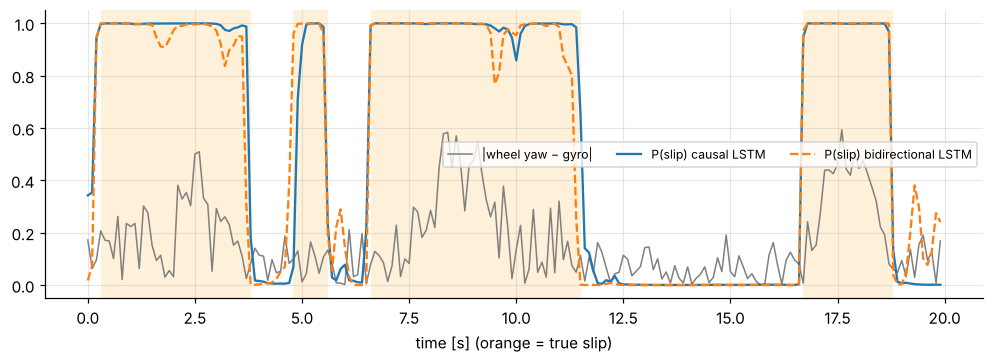

In [17]:
i = ex
t = np.arange(len(Xte_l[i])) * DT
X = Xte_l[i]
plt.figure(figsize=(11, 3.4))
for k in np.where(yte[i]["slip"] > 0)[0]: plt.axvspan(t[k], t[k] + DT, color="orange", alpha=.15, lw=0)
plt.plot(t, np.abs((X[:, 3] - X[:, 2]) / TRACK - X[:, 4]), color="grey", lw=1, label="|wheel yaw − gyro|")
for name, ls in (("causal LSTM", "-"), ("bidirectional LSTM", "--")):
    plt.plot(t, torch.sigmoid(slip_prob[name][i][:, 0]).numpy(), ls, label=f"P(slip) {name}")
plt.legend(ncol=3, fontsize=8); plt.xlabel("time [s] (orange = true slip)"); plt.show()

## 9. What to remember

1. **A hidden state is a state estimate.** If you can write the physics as xₜ = f(xₜ₋₁, uₜ),
   the recurrence is already there; the network learns f.
2. **Pick the shape from the question**: one label per run → many-to-one; one per step →
   many-to-many; future values → sequence-to-sequence (Supplement B).
3. **Integration needs memory with gain 1.** Vanilla RNNs cannot hold it; LSTM/GRU can — and
   only after their gates are opened and training has found the long path.
4. **Measure the gradient reach** (∂output/∂input at lag k). It tells you directly how far back
   a model can learn from.
5. **Look inside**: correlate hidden units with the physical state. Expect a distributed,
   not-quite-textbook solution.
6. **Ragged batches**: a forward model's output at L−1 ignores later padding, but `h_n` and
   bidirectional layers do not — pack, or bucket by length (fastest on CPU).
7. **Bidirectional only if the future matters and you can wait for it.**
8. **Always beat the physics baseline** (gyro integration, wheel odometry, a threshold rule).
   On terrain, five hand features tie the best RNN — that is a result worth reporting.

## 10. Exercises

1. **Gyro bias, made visible.** Set `GYRO_BIAS = 0` and retrain the heading models. Which
   baseline improves, and does the gap between the GRU and the gyro baseline close? Explain.
2. **Feed the network a physics feature.** Add the integrated gyro (cumulative sum) as an eighth
   input channel. Does the vanilla RNN now succeed? What does that say about what was hard?
3. **Half-life of a trained RNN.** Compute the spectral radius ρ(W_hh) of the trained vanilla
   RNN and its implied half-life. Compare with the gradient-reach curve.
4. **Wrap-around.** Heading is an angle. Replace the regression target ψ by (cos ψ, sin ψ) and
   report the angular error. Which runs improve?
5. **Bidirectional where it should help.** Change the slip generator so slip is only detectable
   from the *recovery* (e.g. a speed dip after the episode). Show that the BiLSTM now wins and
   the causal LSTM has a latency.
6. **Online terrain decisions.** Using the prefix curve, choose the shortest time after which the
   rover may switch its traction controller with ≥ 90 % accuracy. Which terrain needs longest?
7. **Pack vs bucket at scale.** Generate runs with *continuous* lengths (not multiples of 10).
   Implement length-sorted batching with small padding + packing and compare speed and accuracy.
8. **A learned Kalman filter.** Implement a 2-state Kalman filter (heading, gyro bias) using the
   wheel yaw rate as a measurement that is ignored when the slip label says slip. How close does
   it get to the GRU? What does the GRU have that the filter doesn't?

## 11. References

* S. Raschka, Y. Liu, V. Mirjalili, *Machine Learning with PyTorch and Scikit-Learn*, Packt, 2022, ch. 15.
* S. Hochreiter, J. Schmidhuber, "Long short-term memory", *Neural Computation* 9(8), 1997.
* K. Cho et al., "Learning phrase representations using RNN encoder–decoder for statistical
  machine translation", *EMNLP*, 2014 (the GRU).
* Y. Bengio, P. Simard, P. Frasconi, "Learning long-term dependencies with gradient descent is
  difficult", *IEEE Trans. Neural Networks* 5(2), 1994.
* R. Jozefowicz, W. Zaremba, I. Sutskever, "An empirical exploration of recurrent network
  architectures", *ICML*, 2015 (forget-gate bias of 1).
* M. Schuster, K. K. Paliwal, "Bidirectional recurrent neural networks", *IEEE Trans. Signal
  Processing* 45(11), 1997.
* S. Thrun, W. Burgard, D. Fox, *Probabilistic Robotics*, MIT Press, 2005 (odometry, Kalman filters).
* T. Haarnoja et al., "Backprop KF: learning discriminative deterministic state estimators", *NeurIPS*, 2016.
* PyTorch documentation: `torch.nn.LSTM`, `torch.nn.GRU`, `torch.nn.utils.rnn.pack_padded_sequence`.

Generated by Claude and customized by

<div align="center">
<img src="https://raw.githubusercontent.com/dewdotninja/sharing-github/refs/heads/master/dewninja_logo50.jpg" alt="dewninja"/>
</div>
<div align="center">dew.ninja 2026</div>